# Decision Tree profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train a tree, choose a validation threshold, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

## Load and inspect the prepared records

The CSV has 150 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv("../dataset/clean_undersampled.csv", low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (549174, 150)
Class balance:
 profitable
0    274587
1    274587
Name: count, dtype: int64


## Create training, validation, and test sets

The test set is held out until the end. The validation set is used to choose the probability threshold. Stratification ensures that the Profit/Loss proportions remain consistent instead of randomly selecting from the entire dataset, so each one is equally considered.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=12, stratify=y)
X_fit, X_validation, y_fit, y_validation = train_test_split(X_train, y_train, test_size=0.20, random_state=12, stratify=y_train)
print("Training rows:", len(X_fit))
print("Validation rows:", len(X_validation))
print("Test rows:", len(X_test))

Training rows: 351471
Validation rows: 87868
Test rows: 109835


## Fill missing values and train the tree

In order to fine tune the parameters that were used in the DecisionTreeClassifier function, a RandomizedSearchCV was first used to compare different combinations such as max tree depth, and the minimum rows needed in order to justify a leaf prediction being considered. 12 randomly selected combinations of settings were attempted, each implementing k-fold validation to fully test the effects of the parameters and compare accuracy consistency. Based on those results, the following parameters were chosen for faster training time on future tweaks.

The active model uses the previously selected values: depth 12, leaf 100, split 50, max_features 0.5, and Gini criterion.

The code can be viewed in the cell below. It is currently commented so the other code can be run as simply as possible.

In [4]:
# search_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("model", DecisionTreeClassifier(random_state=12)),
# ])
# settings_to_test = {
#     "model__max_depth": [4, 8, 12, 16, 20, None],  # Maximum tree depth.
#     "model__min_samples_leaf": [10, 25, 50, 100],  # Minimum rows in a leaf.
#     "model__min_samples_split": [20, 50, 100],  # Minimum rows needed to split.
#     "model__max_features": ["sqrt", 0.25, 0.5, None],  # Features considered at each split.
#     "model__criterion": ["gini", "entropy", "log_loss"],  # Split-quality formula.
# }
# search = RandomizedSearchCV(
#     search_pipeline,
#     settings_to_test,
#     n_iter=12,  # Try 12 randomly selected combinations.
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=12),  # Five validation folds.
#     scoring="average_precision",  # Compare probability ranking with AP.
#     random_state=12,
#     n_jobs=-1, # Use all available CPU cores
# )
# search.fit(X_fit, y_fit)  # The best result can be read with search.best_params_.

After having used cross validation to select parameters, the model can be trained as follows.

The imputer simply addresses values with missing data. If a cell is missing data, the DecisionTreeClassifier will replace the null value with the median of that column.

In [5]:
imputer = SimpleImputer(strategy="median")
X_fit_imputed = imputer.fit_transform(X_fit)
X_validation_imputed = imputer.transform(X_validation)
model = DecisionTreeClassifier(max_depth=12, min_samples_leaf=100, min_samples_split=50, max_features=0.5, criterion="gini", random_state=12)
model.fit(X_fit_imputed, y_fit)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",0.5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",12
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

## Choose a precision-oriented threshold

The model gives each row a Profit probability. F0.5 gives precision more weight than recall, so the selected threshold emphasizes avoiding false-positive Profit predictions. The decision to prioritize Precision over Recall is justified based on the following situation. When a loan is accepted, a False Positive reassurance that the loan will not be risky and ends up either being a loss in profit or a default is more consequential than a loan application that would be safe to approve being declined.

In [6]:
validation_probability = model.predict_proba(X_validation_imputed)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_validation, validation_probability)
f05_values = (1 + 0.5**2) * precision_values[:-1] * recall_values[:-1] / (0.5**2 * precision_values[:-1] + recall_values[:-1] + 1e-12)
best_index = np.argmax(f05_values)
selected_threshold = thresholds[best_index]
validation_prediction = (validation_probability >= selected_threshold).astype(int)

print("Selected threshold:", round(selected_threshold, 4))
print("Validation accuracy:", round(accuracy_score(y_validation, validation_prediction), 4))
print("Validation precision:", round(precision_values[best_index], 4))
print("Validation recall:", round(recall_values[best_index], 4))

Selected threshold: 0.5266
Validation accuracy: 0.6531
Validation precision: 0.6716
Validation recall: 0.5992


## Evaluate the held-out test data

The imputer is fitted again on all training rows, then the model is retrained. The test data is adjusted with those training medians and evaluated for final results.

In [7]:
full_imputer = SimpleImputer(strategy="median")
X_train_imputed = full_imputer.fit_transform(X_train)
X_test_imputed = full_imputer.transform(X_test)
model.fit(X_train_imputed, y_train)
test_probability = model.predict_proba(X_test_imputed)[:, 1]
test_prediction = (test_probability >= selected_threshold).astype(int)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))
print(classification_report(y_test, test_prediction, target_names=["Loss", "Profit"], zero_division=0))

Accuracy: 0.6527
Precision: 0.668
Recall: 0.6072
F1-score: 0.6362
ROC-AUC: 0.7096
Average precision: 0.7018
              precision    recall  f1-score   support

        Loss       0.64      0.70      0.67     54917
      Profit       0.67      0.61      0.64     54918

    accuracy                           0.65    109835
   macro avg       0.65      0.65      0.65    109835
weighted avg       0.65      0.65      0.65    109835



## Plot the test results

The confusion matrix displayed shows True Positive as [Profit, Profit], so correctly predicted Profit.

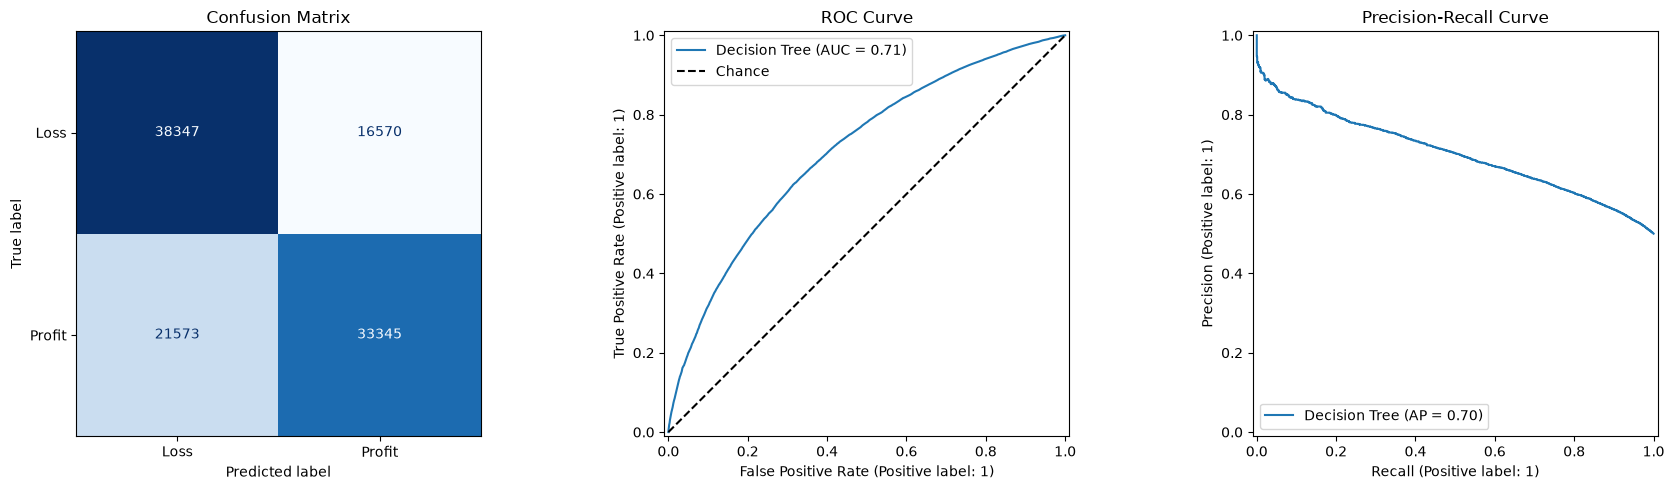

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="Decision Tree", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="Decision Tree", ax=axes[2])
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## Plotting the Decision Tree
Max depth of 4, you can see how different features are combined into nodes

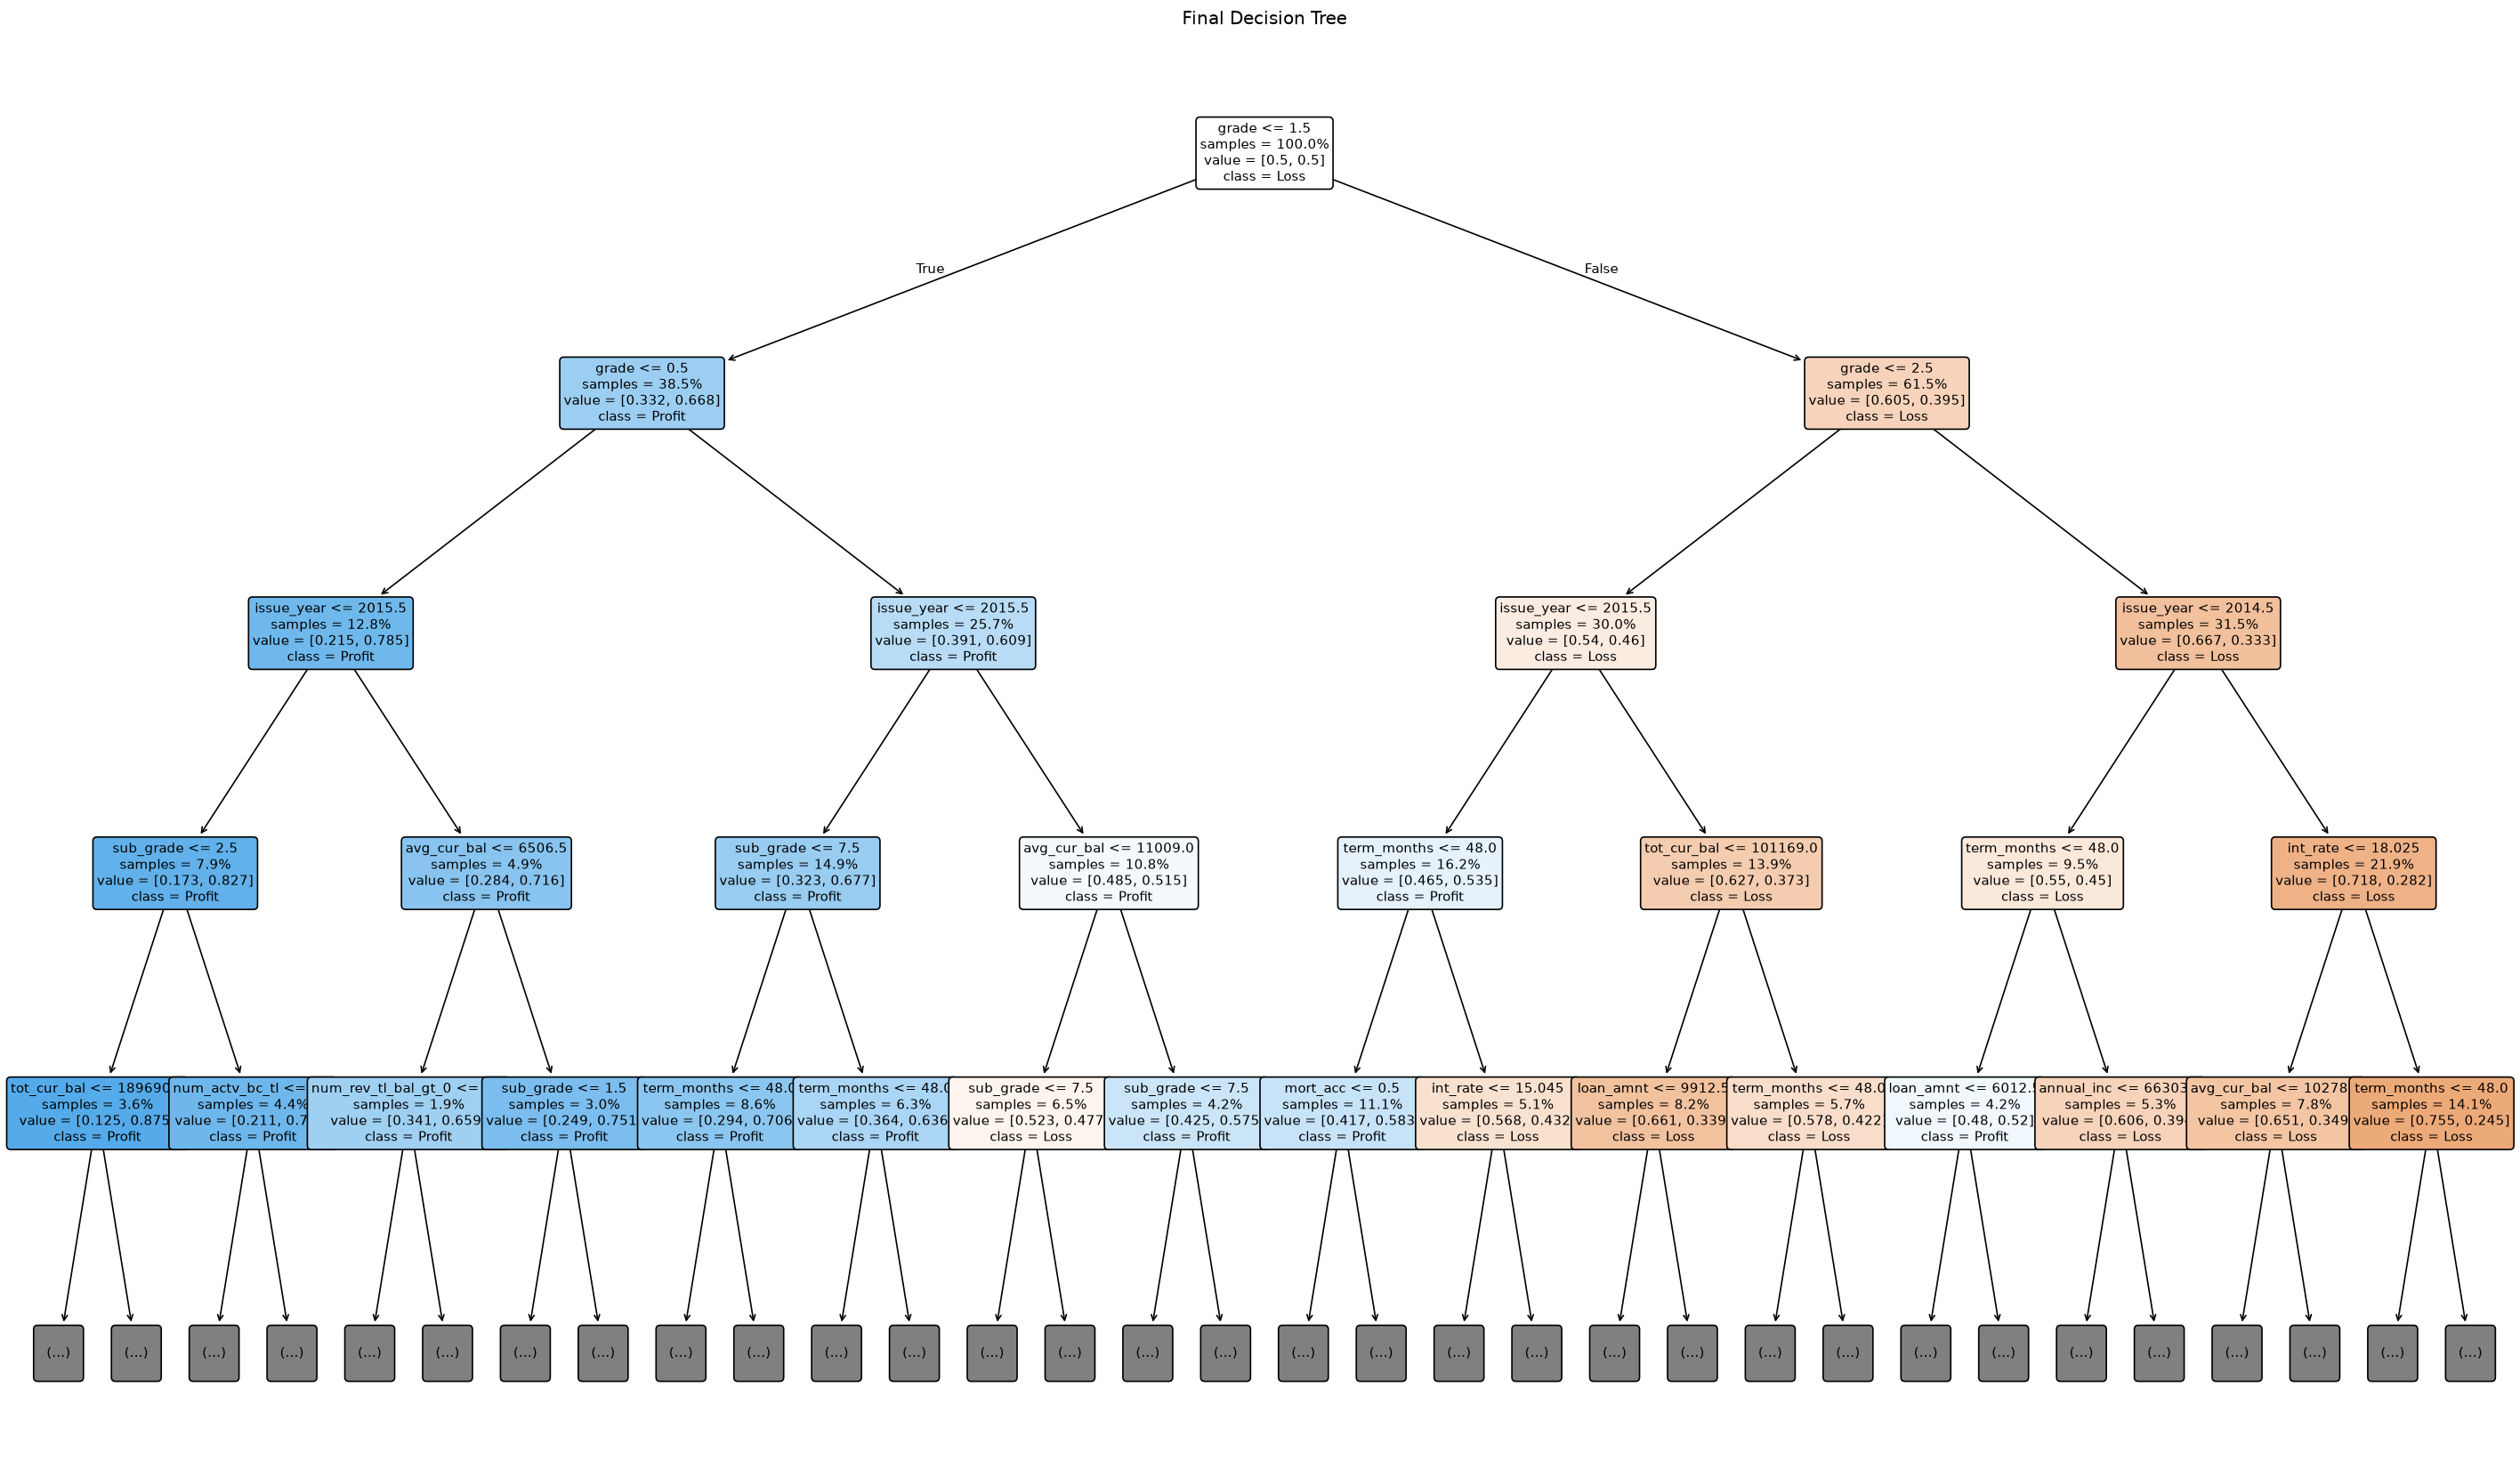

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 14), dpi=120)
plot_tree(
    model,
    max_depth=4,
    feature_names=X.columns,
    class_names=["Loss", "Profit"],
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=9,
)
plt.title("Final Decision Tree")
plt.tight_layout()
plt.show()